<a href="https://colab.research.google.com/github/Anyangos/Digital-Twin/blob/llm-architecture-anatomy/02_llm_architecture_anatomy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 1.2: LLM Big Picture & Anatomy for Digital Twins

## Learning Objectives
- Understand the overall architecture of LLMs
- Learn about tokens, tokenization, and embeddings
- See how different components work together
- Apply these concepts to building a language-enabled digital twin

## Key Insight
> "Know the different bits of the LLM architecture and how they work together to generate outputs."

## Digital Twin Context
Today we'll enhance our digital twin with language understanding capabilities. By the end, your digital twin will:
- Convert text to numerical representations
- Understand word relationships and context
- Process sequences of information

In [3]:
# Import required libraries
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter, defaultdict
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import re

# Set style
sns.set_style('whitegrid')
np.random.seed(42)

print("✅ Libraries loaded successfully!")

✅ Libraries loaded successfully!


---
## Part 1: Tokenization - Breaking Text into Pieces

Before an LLM can process text, it needs to convert words into tokens.

### 1.1 Simple Word Tokenization

In [4]:
def simple_tokenize(text):
    """
    Basic tokenization: split text into words.

    Args:
        text: Input string

    Returns:
        list: Tokens
    """
    # Convert to lowercase and split
    text = text.lower()
    # Remove punctuation and split
    tokens = re.findall(r'\b\w+\b', text)
    return tokens

# Example: Digital twin's user description
user_description = """
I love running in the morning before work. Coffee is essential.
I enjoy reading science fiction and coding in Python.
Weekends are for family time and outdoor activities.
"""

tokens = simple_tokenize(user_description)
print("Original text:")
print(user_description)
print(f"\nTokens ({len(tokens)} total):")
print(tokens[:20], "...")  # Show first 20

# Count token frequencies
token_counts = Counter(tokens)
print("\nMost common tokens:")
for token, count in token_counts.most_common(10):
    print(f"  {token}: {count}")

Original text:

I love running in the morning before work. Coffee is essential.
I enjoy reading science fiction and coding in Python.
Weekends are for family time and outdoor activities.


Tokens (28 total):
['i', 'love', 'running', 'in', 'the', 'morning', 'before', 'work', 'coffee', 'is', 'essential', 'i', 'enjoy', 'reading', 'science', 'fiction', 'and', 'coding', 'in', 'python'] ...

Most common tokens:
  i: 2
  in: 2
  and: 2
  love: 1
  running: 1
  the: 1
  morning: 1
  before: 1
  work: 1
  coffee: 1


### 🎯 Exercise 1.1 (Easy): Personal Tokenization

**Task**: Write a short description of yourself (3-4 sentences) and tokenize it.

**Questions**:
1. How many unique tokens do you have?
2. What are your most frequent tokens?
3. How does tokenization help the digital twin understand you?

In [ ]:
# YOUR CODE HERE
my_description = """
Write your description here...
"""

# Tokenize and analyze
my_tokens = simple_tokenize(my_description)

# Your analysis:
print(f"Total tokens: {len(my_tokens)}")
print(f"Unique tokens: {len(set(my_tokens))}")
# Add more analysis


Total tokens: 4
Unique tokens: 4


### 1.2 Subword Tokenization (BPE-like)

Real LLMs use subword tokenization to handle rare words and morphology.

In [5]:
class SimpleTokenizer:
    """Simple subword tokenizer inspired by BPE."""

    def __init__(self, vocab_size=100):
        self.vocab_size = vocab_size
        self.word_to_id = {}
        self.id_to_word = {}
        self.subword_vocab = []

    def build_vocab(self, texts):
        """
        Build vocabulary from texts.

        Args:
            texts: List of text strings
        """
        # Get all words
        all_words = []
        for text in texts:
            all_words.extend(simple_tokenize(text))

        # Count frequencies
        word_counts = Counter(all_words)

        # Take most common words
        most_common = word_counts.most_common(self.vocab_size)

        # Build vocabulary
        special_tokens = ['<PAD>', '<UNK>', '<START>', '<END>']
        self.word_to_id = {word: i for i, word in enumerate(special_tokens)}

        for i, (word, count) in enumerate(most_common):
            self.word_to_id[word] = i + len(special_tokens)

        self.id_to_word = {i: word for word, i in self.word_to_id.items()}

        print(f"Vocabulary built: {len(self.word_to_id)} tokens")

    def encode(self, text):
        """
        Convert text to token IDs.

        Args:
            text: Input string

        Returns:
            list: Token IDs
        """
        tokens = simple_tokenize(text)
        unk_id = self.word_to_id['<UNK>']
        return [self.word_to_id.get(token, unk_id) for token in tokens]

    def decode(self, token_ids):
        """
        Convert token IDs back to text.

        Args:
            token_ids: List of token IDs

        Returns:
            str: Decoded text
        """
        tokens = [self.id_to_word.get(id, '<UNK>') for id in token_ids]
        # Filter special tokens
        tokens = [t for t in tokens if not t.startswith('<')]
        return ' '.join(tokens)

# Build tokenizer for digital twin
training_texts = [
    user_description,
    "I prefer tea over coffee in the afternoon",
    "Running helps me stay focused and energized",
    "Python is my favorite programming language",
    "I love spending time with family on weekends",
]

tokenizer = SimpleTokenizer(vocab_size=50)
tokenizer.build_vocab(training_texts)

# Test encoding and decoding
test_text = "I love running and coding in Python"
encoded = tokenizer.encode(test_text)
decoded = tokenizer.decode(encoded)

print(f"\nOriginal: {test_text}")
print(f"Encoded: {encoded}")
print(f"Decoded: {decoded}")

Vocabulary built: 45 tokens

Original: I love running and coding in Python
Encoded: [4, 7, 8, 6, 24, 5, 12]
Decoded: i love running and coding in python


### 🎯 Exercise 1.2 (Intermediate): Vocabulary Analysis

**Task**: Analyze what happens with different vocabulary sizes.

**Questions**:
1. What happens when you use a very small vocabulary (vocab_size=10)?
2. How many unknown tokens do you get?
3. What's the trade-off between vocabulary size and coverage?

Vocabulary built: 14 tokens
Vocabulary built: 24 tokens
Vocabulary built: 45 tokens
Vocabulary built: 45 tokens

--- Analysis Summary ---
Vocab Size  10: 9 / 16 unknown tokens (56.2%)
Vocab Size  20: 7 / 16 unknown tokens (43.8%)
Vocab Size  50: 4 / 16 unknown tokens (25.0%)
Vocab Size 100: 4 / 16 unknown tokens (25.0%)


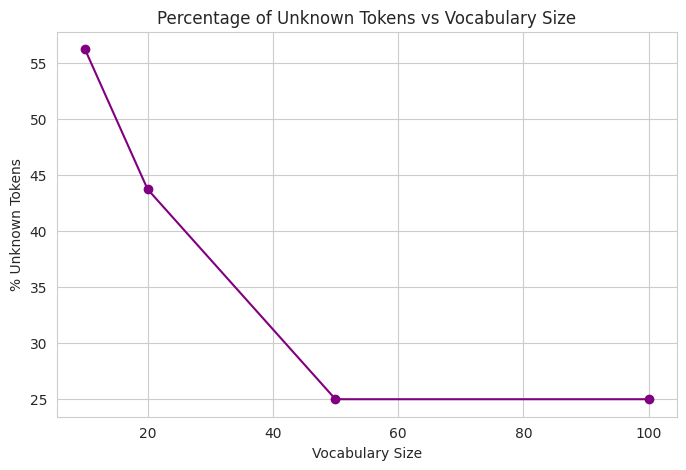

In [6]:
import matplotlib.pyplot as plt

# Experiment with different vocabulary sizes
vocab_sizes = [10, 20, 50, 100]
test_texts = [
    "I love running and programming",
    "Coffee is essential for productivity",
    "Weekend activities include hiking and reading",
]

# For each vocabulary size, count unknown tokens
results = []
for size in vocab_sizes:
    # Create and build tokenizer vocabulary using the training corpus
    tokens_tokenizer = SimpleTokenizer(vocab_size=size)
    tokens_tokenizer.build_vocab(training_texts)

    total_tokens = 0
    unk_tokens = 0
    unk_id = tokens_tokenizer.word_to_id['<UNK>']

    # Encode test texts and count unknowns
    for txt in test_texts:
        encoded_ids = tokens_tokenizer.encode(txt)
        total_tokens += len(encoded_ids)
        for token_id in encoded_ids:
            if token_id == unk_id:
                unk_tokens += 1

    # Store results
    results.append({
        'vocab_size': size,
        'total_tokens': total_tokens,
        'unk_tokens': unk_tokens,
        'unk_ratio': unk_tokens / total_tokens if total_tokens > 0 else 0
    })

# Print the results summary
print("\n--- Analysis Summary ---")
for r in results:
    print(f"Vocab Size {r['vocab_size']:>3}: {r['unk_tokens']} / {r['total_tokens']} unknown tokens ({r['unk_ratio']*100:.1f}%)")

# Visualize results
plt.figure(figsize=(8, 5))
plt.plot([r['vocab_size'] for r in results], [r['unk_ratio'] * 100 for r in results], marker='o', color='purple')
plt.title('Percentage of Unknown Tokens vs Vocabulary Size')
plt.xlabel('Vocabulary Size')
plt.ylabel('% Unknown Tokens')
plt.grid(True)
plt.show()

---
## Part 2: Embeddings - Giving Meaning to Tokens

Embeddings convert tokens into dense vectors that capture semantic meaning.

### 2.1 Creating Simple Embeddings

In [7]:
class SimpleEmbedding:
    """Simple word embedding layer."""

    def __init__(self, vocab_size, embedding_dim):
        """
        Initialize embedding matrix.

        Args:
            vocab_size: Size of vocabulary
            embedding_dim: Dimension of embedding vectors
        """
        self.vocab_size = vocab_size
        self.embedding_dim = embedding_dim
        # Initialize with random values
        self.embeddings = np.random.randn(vocab_size, embedding_dim) * 0.1

    def embed(self, token_ids):
        """
        Get embeddings for token IDs.

        Args:
            token_ids: List of token IDs

        Returns:
            np.array: Embedding vectors
        """
        return self.embeddings[token_ids]

    def similarity(self, id1, id2):
        """
        Calculate cosine similarity between two tokens.

        Args:
            id1, id2: Token IDs

        Returns:
            float: Cosine similarity
        """
        vec1 = self.embeddings[id1]
        vec2 = self.embeddings[id2]

        # Cosine similarity
        dot_product = np.dot(vec1, vec2)
        norm1 = np.linalg.norm(vec1)
        norm2 = np.linalg.norm(vec2)

        return dot_product / (norm1 * norm2)

# Create embeddings for our vocabulary
vocab_size = len(tokenizer.word_to_id)
embedding_dim = 16  # Small dimension for visualization

embedding_layer = SimpleEmbedding(vocab_size, embedding_dim)

# Test with some words
test_words = ['running', 'coding', 'coffee', 'python', 'family']
print("Word embeddings:")
for word in test_words:
    if word in tokenizer.word_to_id:
        token_id = tokenizer.word_to_id[word]
        embedding = embedding_layer.embed([token_id])[0]
        print(f"\n{word} (ID: {token_id}):")
        print(f"  Embedding (first 5 dims): {embedding[:5]}")
        print(f"  Norm: {np.linalg.norm(embedding):.3f}")

Word embeddings:

running (ID: 8):
  Embedding (first 5 dims): [ 0.00996514 -0.05034757 -0.15506634  0.0068563  -0.10623037]
  Norm: 0.381

coding (ID: 24):
  Embedding (first 5 dims): [-0.07591327  0.01503938  0.0341756   0.18761708  0.09504238]
  Norm: 0.442

coffee (ID: 10):
  Embedding (first 5 dims): [-0.09746817  0.07870846  0.11585956 -0.08206823  0.09633761]
  Norm: 0.345

python (ID: 12):
  Embedding (first 5 dims): [ 0.02140937 -0.12457388  0.01731809  0.03853174 -0.08838574]
  Norm: 0.315

family (ID: 14):
  Embedding (first 5 dims): [-0.04719319  0.10889506  0.006428   -0.10777448 -0.07153037]
  Norm: 0.385


### 2.2 Training Embeddings with Context

Embeddings learn meaning from co-occurrence patterns (Word2Vec style).

In [8]:
def train_embeddings(tokenizer, texts, embedding_dim=16, window_size=2,
                     learning_rate=0.01, epochs=100):
    """
    Train embeddings using skip-gram approach.

    Args:
        tokenizer: Tokenizer instance
        texts: List of training texts
        embedding_dim: Dimension of embeddings
        window_size: Context window size
        learning_rate: Learning rate
        epochs: Number of training epochs

    Returns:
        SimpleEmbedding: Trained embedding layer
    """
    vocab_size = len(tokenizer.word_to_id)
    embeddings = SimpleEmbedding(vocab_size, embedding_dim)

    # Create training pairs (center word, context word)
    training_pairs = []
    for text in texts:
        token_ids = tokenizer.encode(text)
        for i, center_id in enumerate(token_ids):
            # Get context window
            start = max(0, i - window_size)
            end = min(len(token_ids), i + window_size + 1)
            context_ids = [token_ids[j] for j in range(start, end) if j != i]
            for context_id in context_ids:
                training_pairs.append((center_id, context_id))

    print(f"Training on {len(training_pairs)} word pairs...")

    # Simple training loop
    for epoch in range(epochs):
        total_loss = 0
        np.random.shuffle(training_pairs)

        for center_id, context_id in training_pairs:
            # Get embeddings
            center_emb = embeddings.embeddings[center_id]
            context_emb = embeddings.embeddings[context_id]

            # Calculate similarity
            similarity = np.dot(center_emb, context_emb)

            # Gradient descent (simplified)
            gradient = context_emb - similarity * center_emb
            embeddings.embeddings[center_id] += learning_rate * gradient

            total_loss += (1 - similarity) ** 2

        if epoch % 20 == 0:
            avg_loss = total_loss / len(training_pairs)
            print(f"Epoch {epoch}: Loss = {avg_loss:.4f}")

    return embeddings

# Train embeddings
trained_embeddings = train_embeddings(tokenizer, training_texts,
                                     embedding_dim=16, epochs=100)

print("\n✅ Embeddings trained!")

Training on 198 word pairs...
Epoch 0: Loss = 0.9954
Epoch 20: Loss = 0.7512
Epoch 40: Loss = 0.2963
Epoch 60: Loss = 0.0714
Epoch 80: Loss = 0.0170

✅ Embeddings trained!


In [ ]:
# Test similarity after training
def find_similar_words(word, tokenizer, embeddings, top_k=5):
    """
    Find most similar words to given word.

    Args:
        word: Query word
        tokenizer: Tokenizer instance
        embeddings: Embedding layer
        top_k: Number of similar words to return

    Returns:
        list: Similar words with similarities
    """
    if word not in tokenizer.word_to_id:
        return None

    word_id = tokenizer.word_to_id[word]
    word_emb = embeddings.embeddings[word_id]

    # Calculate similarities with all words
    similarities = []
    for other_word, other_id in tokenizer.word_to_id.items():
        if other_word.startswith('<') or other_id == word_id:
            continue
        sim = embeddings.similarity(word_id, other_id)
        similarities.append((other_word, sim))

    # Sort by similarity
    similarities.sort(key=lambda x: x[1], reverse=True)
    return similarities[:top_k]

# Test with some words
test_words = ['running', 'python', 'coffee', 'love']
for word in test_words:
    similar = find_similar_words(word, tokenizer, trained_embeddings)
    if similar:
        print(f"\nWords similar to '{word}':")
        for similar_word, sim in similar:
            print(f"  {similar_word}: {sim:.3f}")


Words similar to 'running':
  love: 0.977
  in: 0.974
  coding: 0.960
  the: 0.947
  i: 0.945

Words similar to 'python':
  in: 0.980
  love: 0.966
  coding: 0.963
  spending: 0.943
  running: 0.943

Words similar to 'coffee':
  work: 0.982
  is: 0.979
  over: 0.979
  the: 0.975
  before: 0.966

Words similar to 'love':
  spending: 0.978
  running: 0.977
  i: 0.976
  in: 0.974
  python: 0.966


### 🎯 Exercise 2.1 (Intermediate): Embedding Visualization

**Task**: Visualize word embeddings in 2D space using dimensionality reduction.

**Steps**:
1. Use PCA or t-SNE to reduce embeddings to 2D
2. Plot the words
3. Identify clusters of related words

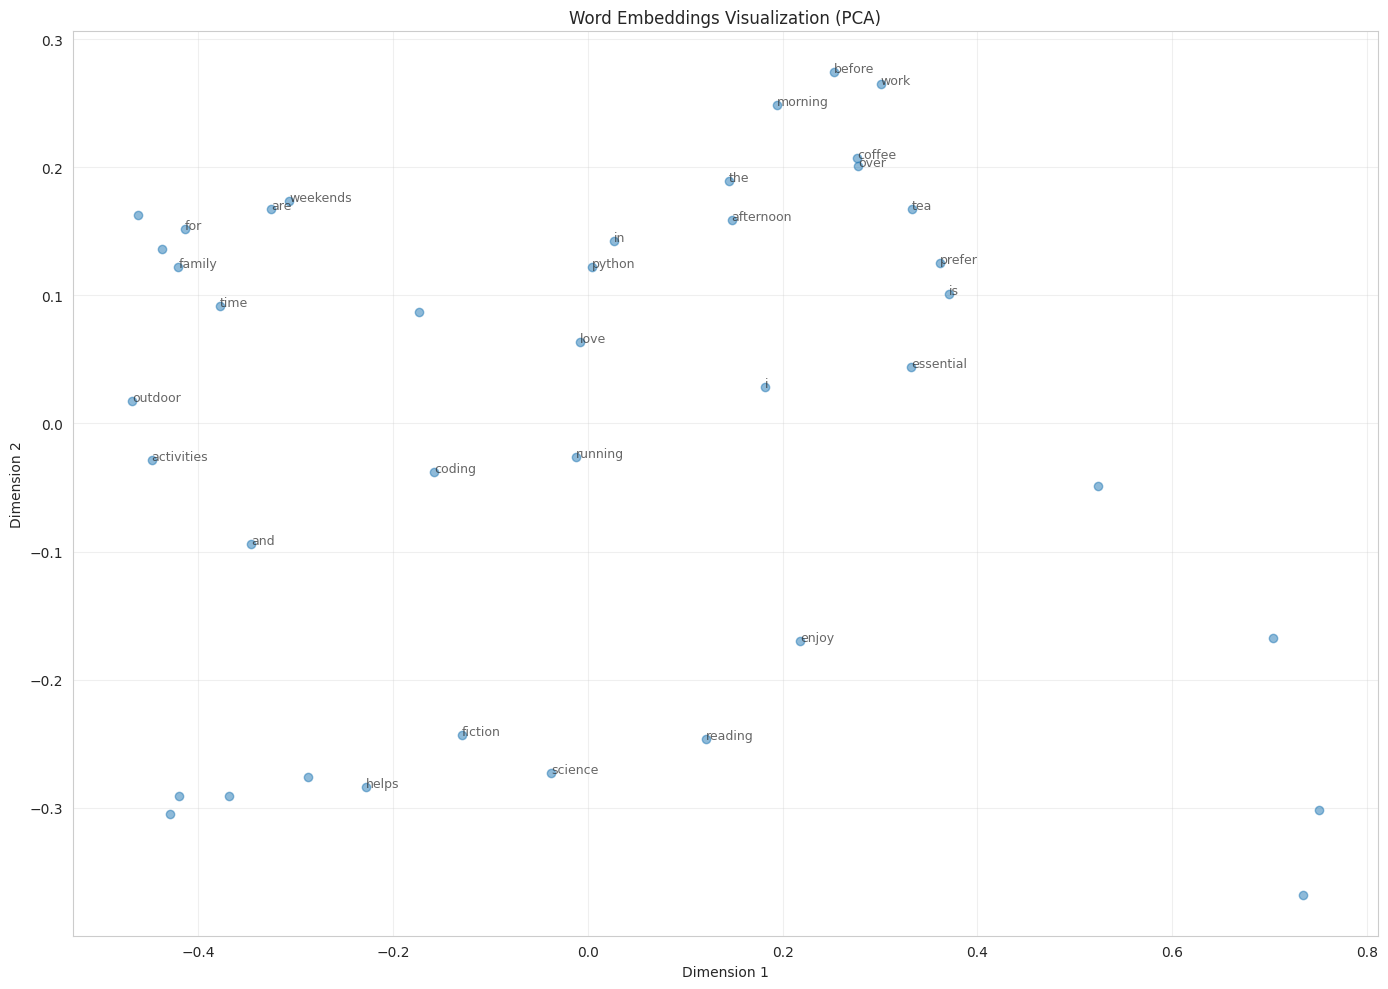

In [9]:
# YOUR CODE HERE
def visualize_embeddings(tokenizer, embeddings, method='pca'):
    """
    Visualize embeddings in 2D.

    Args:
        tokenizer: Tokenizer instance
        embeddings: Embedding layer
        method: 'pca' or 'tsne'
    """
    # Get all embeddings (excluding special tokens)
    words = []
    vectors = []

    for word, idx in tokenizer.word_to_id.items():
        if not word.startswith('<'):
            words.append(word)
            vectors.append(embeddings.embeddings[idx])

    vectors = np.array(vectors)

    # Reduce dimensionality
    if method == 'pca':
        reducer = PCA(n_components=2)
    else:
        reducer = TSNE(n_components=2, random_state=42)

    coords_2d = reducer.fit_transform(vectors)

    # Plot
    plt.figure(figsize=(14, 10))
    plt.scatter(coords_2d[:, 0], coords_2d[:, 1], alpha=0.5)

    # Annotate words
    for i, word in enumerate(words[:30]):  # Show first 30 to avoid clutter
        plt.annotate(word, (coords_2d[i, 0], coords_2d[i, 1]),
                    fontsize=9, alpha=0.7)

    plt.title(f'Word Embeddings Visualization ({method.upper()})')
    plt.xlabel('Dimension 1')
    plt.ylabel('Dimension 2')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

# Visualize
visualize_embeddings(tokenizer, trained_embeddings, method='pca')

---
## Part 3: LLM Architecture Overview

Now let's see how these components fit into the bigger picture.

### 3.1 The LLM Pipeline

In [10]:
class SimpleLLMPipeline:
    """
    Simplified LLM pipeline showing major components.
    """

    def __init__(self, tokenizer, embeddings):
        self.tokenizer = tokenizer
        self.embeddings = embeddings
        self.processing_steps = []

    def process(self, text, verbose=True):
        """
        Process text through the pipeline.

        Args:
            text: Input text
            verbose: Print intermediate steps

        Returns:
            dict: Processing results
        """
        results = {}

        # Step 1: Tokenization
        if verbose:
            print("Step 1: Tokenization")
            print("  Input text:", text)

        tokens = simple_tokenize(text)
        token_ids = self.tokenizer.encode(text)

        if verbose:
            print(f"  Tokens: {tokens}")
            print(f"  Token IDs: {token_ids}")

        results['tokens'] = tokens
        results['token_ids'] = token_ids

        # Step 2: Embedding
        if verbose:
            print("\nStep 2: Embedding")

        embedded = self.embeddings.embed(token_ids)

        if verbose:
            print(f"  Embedding shape: {embedded.shape}")
            print(f"  (sequence_length={len(token_ids)}, embedding_dim={embedded.shape[1]})")

        results['embeddings'] = embedded

        # Step 3: Attention (simplified - just mean pooling)
        if verbose:
            print("\nStep 3: Contextual Processing (Simplified)")

        # Simple mean pooling as placeholder
        contextualized = np.mean(embedded, axis=0)

        if verbose:
            print(f"  Contextualized representation shape: {contextualized.shape}")

        results['contextualized'] = contextualized

        # Step 4: Output projection (simplified)
        if verbose:
            print("\nStep 4: Output Generation (Simplified)")
            print("  → In real LLMs, this produces probability distribution over vocabulary")

        return results

# Create pipeline
pipeline = SimpleLLMPipeline(tokenizer, trained_embeddings)

# Test with digital twin input
test_input = "I love running and coding"
print("=" * 60)
print("PROCESSING THROUGH LLM PIPELINE")
print("=" * 60 + "\n")

results = pipeline.process(test_input, verbose=True)

print("\n" + "=" * 60)
print("✅ Processing complete!")
print("=" * 60)

PROCESSING THROUGH LLM PIPELINE

Step 1: Tokenization
  Input text: I love running and coding
  Tokens: ['i', 'love', 'running', 'and', 'coding']
  Token IDs: [4, 7, 8, 6, 24]

Step 2: Embedding
  Embedding shape: (5, 16)
  (sequence_length=5, embedding_dim=16)

Step 3: Contextual Processing (Simplified)
  Contextualized representation shape: (16,)

Step 4: Output Generation (Simplified)
  → In real LLMs, this produces probability distribution over vocabulary

✅ Processing complete!


### 🎯 Exercise 3.1 (Conceptual): Architecture Understanding

**Questions**:

1. Why is tokenization necessary before embedding?
2. What information is captured in embeddings?
3. What would happen if we skipped the embedding step and used one-hot encoding instead?
4. How does sequence length affect computational cost?
5. In a real LLM, what happens after the "contextual processing" step?

Write your answers below:

**Your Answers:**

1. Why tokenization is necessary:
   -

2. Information in embeddings:
   -

3. One-hot encoding vs embeddings:
   -

4. Sequence length impact:
   -

5. After contextual processing:
   -

### 3.2 Comparing Different Embedding Dimensions

In [11]:
# Experiment with different embedding dimensions
dimensions = [4, 8, 16, 32]

print("Comparing embedding dimensions:\n")
for dim in dimensions:
    emb = SimpleEmbedding(vocab_size, dim)

    # Calculate memory usage
    memory_mb = (vocab_size * dim * 4) / (1024 * 1024)  # 4 bytes per float

    print(f"Dimension {dim}:")
    print(f"  Parameters: {vocab_size * dim:,}")
    print(f"  Memory: {memory_mb:.2f} MB")
    print(f"  Expressiveness: {'Low' if dim < 16 else 'Medium' if dim < 64 else 'High'}")
    print()

Comparing embedding dimensions:

Dimension 4:
  Parameters: 180
  Memory: 0.00 MB
  Expressiveness: Low

Dimension 8:
  Parameters: 360
  Memory: 0.00 MB
  Expressiveness: Low

Dimension 16:
  Parameters: 720
  Memory: 0.00 MB
  Expressiveness: Medium

Dimension 32:
  Parameters: 1,440
  Memory: 0.01 MB
  Expressiveness: Medium



### 🎯 Exercise 3.2 (Advanced): Build a Mini Language Model

**Task**: Create a simple language model that can predict the next word.

**Requirements**:
1. Use the tokenizer and embeddings we created
2. Implement a simple prediction mechanism
3. Test with different input sequences
4. Measure prediction accuracy

**Hint**: You can use the embeddings to find the most similar word to a context representation.

In [ ]:
class MiniLanguageModel:
    """
    Simple language model for next word prediction.
    """

    def __init__(self, tokenizer, embeddings):
        self.tokenizer = tokenizer
        self.embeddings = embeddings
        # Build context patterns from training data
        self.context_patterns = self._build_patterns()

    def _build_patterns(self):
        """Build context → next word patterns from training data."""
        patterns = defaultdict(Counter)

        # Use the global training_texts corpus
        for text in training_texts:
            tokens = simple_tokenize(text)
            for i in range(len(tokens) - 1):
                current_word = tokens[i]
                next_word = tokens[i+1]
                patterns[current_word][next_word] += 1
        return patterns

    def predict_next_word(self, context):
        """
        Predict the most likely next word.

        Args:
            context: String of context words

        Returns:
            str: Predicted next word
        """
        tokens = simple_tokenize(context)
        if not tokens:
            return "<UNK>"

        last_word = tokens[-1]

        # Scenario 1: We have direct pattern statistics for this word
        if last_word in self.context_patterns and self.context_patterns[last_word]:
            return self.context_patterns[last_word].most_common(1)[0][0]

        # Scenario 2:
        # Find the most semantically similar word in vocabulary that *does* have transition patterns
        if last_word in self.tokenizer.word_to_id:
            last_word_id = self.tokenizer.word_to_id[last_word]
            best_sim = -1.0
            best_fallback_word = None

            for word, word_id in self.tokenizer.word_to_id.items():
                if word.startswith('<') or word == last_word:
                    continue
                # Only consider words we actually have transitions for
                if word in self.context_patterns and self.context_patterns[word]:
                    sim = self.embeddings.similarity(last_word_id, word_id)
                    if sim > best_sim:
                        best_sim = sim
                        best_fallback_word = word

            if best_fallback_word:
                return self.context_patterns[best_fallback_word].most_common(1)[0][0]

        return "<UNK>"

    def generate_sequence(self, start_text, num_words=5):
        """
        Generate a sequence of words.

        Args:
            start_text: Starting context
            num_words: Number of words to generate

        Returns:
            str: Generated text
"""
        generated = simple_tokenize(start_text)
        current_context = start_text

        for _ in range(num_words):
            next_word = self.predict_next_word(current_context)
            if next_word == "<UNK>":
                break
            generated.append(next_word)
            current_context = " ".join(generated)

        return " ".join(generated)

# Test your model
model = MiniLanguageModel(tokenizer, trained_embeddings)
prediction = model.predict_next_word("I love")
print(f"Next word prediction after 'I love': {prediction}")

print("\nGenerated Sequence:")
print(model.generate_sequence("I love", num_words=5))

Next word prediction after 'I love': running

Generated Sequence:
i love running in the morning before


---
## Part 4: Digital Twin Integration

Let's bring everything together for our digital twin!

### 4.1 Digital Twin Language Encoder

In [12]:
class DigitalTwinEncoder:
    """
    Encode user descriptions into vector representations.
    """

    def __init__(self, tokenizer, embeddings):
        self.tokenizer = tokenizer
        self.embeddings = embeddings
        self.user_profile = None

    def encode_user(self, description):
        """
        Encode user description into a profile vector.

        Args:
            description: User description text

        Returns:
            np.array: User profile vector
        """
        # Tokenize
        token_ids = self.tokenizer.encode(description)

        # Embed - returns the 16-dimensional embedding vectors
        embedded = self.embeddings.embed(token_ids)

        # Pool (mean pooling) - averages all word vectors
        profile = np.mean(embedded, axis=0)

        self.user_profile = profile
        return profile

    def compare_descriptions(self, desc1, desc2):
        """
        Compare similarity between two descriptions.

        Args:
            desc1, desc2: Description texts

        Returns:
            float: Similarity score
        """
        profile1 = self.encode_user(desc1)
        profile2 = self.encode_user(desc2)

        # Cosine similarity
        similarity = np.dot(profile1, profile2) / (
            np.linalg.norm(profile1) * np.linalg.norm(profile2)
        )

        return similarity

    def find_interests(self, description):
        """
        Extract key interests from description.

        Args:
            description: User description

        Returns:
            list: Key interest words
        """
        tokens = simple_tokenize(description)
        token_ids = self.tokenizer.encode(description)

        # Get embeddings
        embedded = self.embeddings.embed(token_ids)

        # Find tokens with highest norm (most "important")
        norms = np.linalg.norm(embedded, axis=1)
        top_indices = np.argsort(norms)[-5:][::-1]

        interests = [tokens[i] for i in top_indices if i < len(tokens)]
        return interests

# Create digital twin encoder
twin_encoder = DigitalTwinEncoder(tokenizer, trained_embeddings)

# Test with different user profiles
user1 = "I love running and outdoor sports. Coffee enthusiast."
user2 = "I enjoy coding in Python and building AI systems."
user3 = "I love running and coding in Python."

print("User Profile Encoding:\n")
profile1 = twin_encoder.encode_user(user1)
print(f"User 1 profile shape: {profile1.shape}")
print(f"Profile vector (first 8 dims): {profile1[:8]}")

print("\n" + "="*60)
print("Comparing User Profiles:\n")

sim_1_2 = twin_encoder.compare_descriptions(user1, user2)
sim_1_3 = twin_encoder.compare_descriptions(user1, user3)
sim_2_3 = twin_encoder.compare_descriptions(user2, user3)

print(f"User 1 vs User 2 similarity: {sim_1_2:.3f}")
print(f"User 1 vs User 3 similarity: {sim_1_3:.3f}")
print(f"User 2 vs User 3 similarity: {sim_2_3:.3f}")

print("\n" + "="*60)
print("Detected Interests:\n")

for i, user in enumerate([user1, user2, user3], 1):
    interests = twin_encoder.find_interests(user)
    print(f"User {i}: {interests}")

User Profile Encoding:

User 1 profile shape: (16,)
Profile vector (first 8 dims): [ 0.33866163 -0.07237815  0.13469448  0.21867139 -0.04905753  0.12383126
  0.24739396 -0.10105272]

Comparing User Profiles:

User 1 vs User 2 similarity: 0.985
User 1 vs User 3 similarity: 0.988
User 2 vs User 3 similarity: 0.968

Detected Interests:

User 1: ['and', 'i', 'coffee', 'running', 'love']
User 2: ['and', 'in', 'i', 'python', 'enjoy']
User 3: ['and', 'in', 'i', 'running', 'love']


### 🎯 Exercise 4.1 (Intermediate): Build Your Digital Twin Profile

**Task**: Create and analyze your own digital twin profile.

**Steps**:
1. Write a detailed description of yourself (interests, habits, preferences)
2. Encode it using the digital twin encoder
3. Compare it with other example profiles
4. Identify detected interests
5. Test how similar descriptions affect similarity scores

In [13]:
# YOUR CODE HERE
my_description = """
I am a computer science student. I am currently undertaking an ATF AI Challenge. I am currently enjoying learning all these new concepts to do with AI. So far I have learned a lot about how AIs make predictions. The stages are: 1. Tokenization. 2. Embedding. 3. Attention. 4. Output. Tokenization is the convertion of raw strings into tokens and mapping each token to its unique numerical identification.
I prefer learning through practicality. Learning to code is an interesting thing. I am learning how to write python functions. I love running python programs. In the morning, I wake up, do my devotions, exercise then sit down and code.
"""

my_twin = DigitalTwinEncoder(tokenizer, trained_embeddings)

# Encode your profile
encoded1 = my_twin.encode_user(my_description)

# Compare with examples
user2 = "I’m a software developer who lives and breathes Python. My main focus is building and deploying AI systems, taking complex problems and solving them through intelligent automation and machine learning."
user3 = "I split my time between two main passions: coding in Python and running. I find that the discipline it takes to train for a run perfectly mirrors the focus needed to debug a complex script."

encoded2 = my_twin.encode_user(user2)
encoded3 = my_twin.encode_user(user3)

comp_1_2 = my_twin.compare_descriptions(my_description, user2)
comp_1_3 = my_twin.compare_descriptions(my_description, user3)
comp_2_3 = my_twin.compare_descriptions(user2, user3)

print(f"User 1 vs User 2 similarity: {comp_1_2:.3f}")
print(f"User 1 vs User 3 similarity: {comp_1_3:.3f}")
print(f"User 2 vs User 3 similarity: {comp_2_3:.3f}")

# Find your interests
my_interests = my_twin.find_interests(my_description)
print(f"My interests are: {my_interests}")
# Analysis


User 1 vs User 2 similarity: 0.994
User 1 vs User 3 similarity: 0.940
User 2 vs User 3 similarity: 0.948
My interests are: ['and', 'and', 'in', 'i', 'i']


---
## Summary & Key Takeaways

### What We Learned:

1. **Tokenization**: Converting text into processable units
   - Word-level vs subword tokenization
   - Vocabulary size trade-offs
   - Handling unknown words

2. **Embeddings**: Dense vector representations of tokens
   - Capture semantic similarity
   - Learn from co-occurrence patterns
   - Enable mathematical operations on meaning

3. **LLM Architecture**: How components work together
   - Tokenization → Embedding → Processing → Output
   - Each step transforms representation
   - Trade-offs between size and capability

4. **Digital Twin Application**: Practical use of these concepts
   - Encoding user profiles
   - Comparing descriptions
   - Interest extraction

### Next Steps:
In the next notebook, we'll explore:
- The Transformer architecture
- Attention mechanisms
- How context is processed
- Building an attention-based digital twin

---
## 🏆 Challenge Project (Advanced)

**Enhanced Digital Twin Language System**

Build a complete system that:

1. **Data Collection**: Gather multiple user descriptions
2. **Training**: Train better embeddings on this data
3. **Clustering**: Group similar users together
4. **Recommendation**: Suggest connections between users
5. **Visualization**: Create an interactive visualization of the user embedding space

**Bonus Challenges**:
- Implement different embedding training methods (CBOW, Skip-gram)
- Add sentiment analysis to profiles
- Create a simple search engine for finding similar users
- Build a recommendation system based on profile similarity

In [14]:
# YOUR CHALLENGE PROJECT CODE HERE
class DigitalTwinLanguageSystem:
  def __init__(self, tokenizer, embeddings):
    self.tokenizer = tokenizer
    self.embeddings = embeddings

    # Store user descriptions in one place
    user_descriptions = []

# Data Collection: Gather multiple user descriptions
def user_data(self, n_users = 5):
  for i in range(n_users):
    user_descriptions.append(input("Write a detailed description of yourself (interests, habits, preferences)."))
  return user_descriptions

# Training: Train better embeddings on this data
training_embeddings = train_embeddings(tokenizer, training_texts,
                                     embedding_dim=16, epochs=500)



Training on 198 word pairs...
Epoch 0: Loss = 0.9864
Epoch 20: Loss = 0.7489
Epoch 40: Loss = 0.3405
Epoch 60: Loss = 0.0927
Epoch 80: Loss = 0.0219
Epoch 100: Loss = 0.0065
Epoch 120: Loss = 0.0026
Epoch 140: Loss = 0.0013
Epoch 160: Loss = 0.0007
Epoch 180: Loss = 0.0005
Epoch 200: Loss = 0.0003
Epoch 220: Loss = 0.0002
Epoch 240: Loss = 0.0001
Epoch 260: Loss = 0.0001
Epoch 280: Loss = 0.0001
Epoch 300: Loss = 0.0000
Epoch 320: Loss = 0.0000
Epoch 340: Loss = 0.0000
Epoch 360: Loss = 0.0000
Epoch 380: Loss = 0.0000
Epoch 400: Loss = 0.0000
Epoch 420: Loss = 0.0000
Epoch 440: Loss = 0.0000
Epoch 460: Loss = 0.0000
Epoch 480: Loss = 0.0000


In [15]:
"""
A production-ready, consolidated script implementing the NLP & Digital Twin pipeline
from the LLM Big Picture & Anatomy lesson. Features include tokenization, vocabulary building,
skip-gram-inspired embedding training, next-word generation, and profile cosine similarity calculations.
"""

import re
from collections import Counter, defaultdict
from typing import List, Dict, Tuple, Optional
import numpy as np
from sklearn.decomposition import PCA

# ==========================================
# 1. Global Configurations
# ==========================================
EMBEDDING_DIM = 16
VOCAB_SIZE = 50
WINDOW_SIZE = 2
LEARNING_RATE = 0.01
EPOCHS = 200
SEED = 42

np.random.seed(SEED)

# ==========================================
# 2. Tokenization Module
# ==========================================

def simple_tokenize(text: str) -> List[str]:
    """
    Basic tokenization: converts text to lowercase and extracts words.
    """
    text = text.lower()
    return re.findall(r'\b\w+\b', text)


class SimpleTokenizer:
    """
    Vocabulary-building tokenizer mapping tokens to integer IDs.
    """
    def __init__(self, vocab_size: int = 100):
        self.vocab_size = vocab_size
        self.word_to_id: Dict[str, int] = {}
        self.id_to_word: Dict[int, str] = {}

    def build_vocab(self, texts: List[str]) -> None:
        all_words = []
        for text in texts:
            all_words.extend(simple_tokenize(text))

        word_counts = Counter(all_words)
        most_common = word_counts.most_common(self.vocab_size)

        special_tokens = ['<PAD>', '<UNK>', '<START>', '<END>']
        self.word_to_id = {word: i for i, word in enumerate(special_tokens)}

        for i, (word, _) in enumerate(most_common):
            self.word_to_id[word] = i + len(special_tokens)

        self.id_to_word = {i: word for word, i in self.word_to_id.items()}

    def encode(self, text: str) -> List[int]:
        tokens = simple_tokenize(text)
        unk_id = self.word_to_id.get('<UNK>', 1)
        return [self.word_to_id.get(token, unk_id) for token in tokens]

    def decode(self, token_ids: List[int]) -> str:
        tokens = [self.id_to_word.get(idx, '<UNK>') for idx in token_ids]
        tokens = [t for t in tokens if not t.startswith('<')]
        return ' '.join(tokens)

# ==========================================
# 3. Embeddings Module
# ==========================================

class SimpleEmbedding:
    """
    Embeds token IDs into continuous, dense vector spaces.
    """
    def __init__(self, vocab_size: int, embedding_dim: int):
        self.vocab_size = vocab_size
        self.embedding_dim = embedding_dim
        self.embeddings = np.random.randn(vocab_size, embedding_dim) * 0.1

    def embed(self, token_ids: List[int]) -> np.ndarray:
        return self.embeddings[token_ids]

    def similarity(self, id1: int, id2: int) -> float:
        vec1 = self.embeddings[id1]
        vec2 = self.embeddings[id2]
        norm1 = np.linalg.norm(vec1)
        norm2 = np.linalg.norm(vec2)
        if norm1 == 0 or norm2 == 0:
            return 0.0
        return float(np.dot(vec1, vec2) / (norm1 * norm2))


def train_embeddings(
    tokenizer: SimpleTokenizer,
    texts: List[str],
    embedding_dim: int = 16,
    window_size: int = 2,
    learning_rate: float = 0.01,
    epochs: int = 100
) -> SimpleEmbedding:
    """
    Optimizes embedding matrices using a skip-gram inspired learning paradigm.
    """
    vocab_size = len(tokenizer.word_to_id)
    embeddings = SimpleEmbedding(vocab_size, embedding_dim)

    training_pairs = []
    for text in texts:
        token_ids = tokenizer.encode(text)
        for i, center_id in enumerate(token_ids):
            start = max(0, i - window_size)
            end = min(len(token_ids), i + window_size + 1)
            context_ids = [token_ids[j] for j in range(start, end) if j != i]
            for context_id in context_ids:
                training_pairs.append((center_id, context_id))

    for epoch in range(epochs):
        np.random.shuffle(training_pairs)
        for center_id, context_id in training_pairs:
            center_emb = embeddings.embeddings[center_id]
            context_emb = embeddings.embeddings[context_id]

            similarity = np.dot(center_emb, context_emb)
            gradient = context_emb - similarity * center_emb
            embeddings.embeddings[center_id] += learning_rate * gradient

    return embeddings

# ==========================================
# 4. Modeling & Alignment Utilities
# ==========================================

class MiniLanguageModel:
    """
    Deterministic & similarity-fallback next word language predictor.
    """
    def __init__(self, tokenizer: SimpleTokenizer, embeddings: SimpleEmbedding, training_texts: List[str]):
        self.tokenizer = tokenizer
        self.embeddings = embeddings
        self.training_texts = training_texts
        self.context_patterns = self._build_patterns()

    def _build_patterns(self) -> Dict[str, Counter]:
        patterns = defaultdict(Counter)
        for text in self.training_texts:
            tokens = simple_tokenize(text)
            for i in range(len(tokens) - 1):
                patterns[tokens[i]][tokens[i+1]] += 1
        return patterns

    def predict_next_word(self, context: str) -> str:
        tokens = simple_tokenize(context)
        if not tokens:
            return "<UNK>"

        last_word = tokens[-1]
        if last_word in self.context_patterns and self.context_patterns[last_word]:
            return self.context_patterns[last_word].most_common(1)[0][0]

        if last_word in self.tokenizer.word_to_id:
            last_word_id = self.tokenizer.word_to_id[last_word]
            best_sim = -1.0
            best_fallback_word = None

            for word, word_id in self.tokenizer.word_to_id.items():
                if word.startswith('<') or word == last_word:
                    continue
                if word in self.context_patterns and self.context_patterns[word]:
                    sim = self.embeddings.similarity(last_word_id, word_id)
                    if sim > best_sim:
                        best_sim = sim
                        best_fallback_word = word

            if best_fallback_word:
                return self.context_patterns[best_fallback_word].most_common(1)[0][0]

        return "<UNK>"

    def generate_sequence(self, start_text: str, num_words: int = 5) -> str:
        generated = simple_tokenize(start_text)
        current_context = start_text

        for _ in range(num_words):
            next_word = self.predict_next_word(current_context)
            if next_word == "<UNK>":
                break
            generated.append(next_word)
            current_context = " ".join(generated)

        return " ".join(generated)


class DigitalTwinEncoder:
    """
    Builds contextual profile representations and interest metrics for a user.
    """
    def __init__(self, tokenizer: SimpleTokenizer, embeddings: SimpleEmbedding):
        self.tokenizer = tokenizer
        self.embeddings = embeddings

    def encode_user(self, description: str) -> np.ndarray:
        token_ids = self.tokenizer.encode(description)
        embedded = self.embeddings.embed(token_ids)
        return np.mean(embedded, axis=0)

    def compare_descriptions(self, desc1: str, desc2: str) -> float:
        profile1 = self.encode_user(desc1)
        profile2 = self.encode_user(desc2)
        norm1 = np.linalg.norm(profile1)
        norm2 = np.linalg.norm(profile2)
        if norm1 == 0 or norm2 == 0:
            return 0.0
        return float(np.dot(profile1, profile2) / (norm1 * norm2))

    def find_interests(self, description: str, top_k: int = 5) -> List[str]:
        tokens = simple_tokenize(description)
        token_ids = self.tokenizer.encode(description)
        embedded = self.embeddings.embed(token_ids)

        norms = np.linalg.norm(embedded, axis=1)
        top_indices = np.argsort(norms)[-top_k:][::-1]

        return [tokens[i] for i in top_indices if i < len(tokens)]

# ==========================================
# 5. Pipeline Execution Block
# ==========================================

if __name__ == "__main__":
    # Example profiles representation
    training_corpus = [
        "I love running in the morning before work. Coffee is essential.",
        "I prefer tea over coffee in the afternoon",
        "Running helps me stay focused and energized",
        "Python is my favorite programming language",
        "I love spending time with family on weekends and outdoor activities",
    ]

    print("Initializing Pipeline Components...")
    custom_tokenizer = SimpleTokenizer(vocab_size=VOCAB_SIZE)
    custom_tokenizer.build_vocab(training_corpus)

    print("\nTraining Word Embeddings...")
    trained_embs = train_embeddings(
        tokenizer=custom_tokenizer,
        texts=training_corpus,
        embedding_dim=EMBEDDING_DIM,
        window_size=WINDOW_SIZE,
        learning_rate=LEARNING_RATE,
        epochs=EPOCHS
    )

    print("\nInitializing Next-Word & Digital Twin Engine...")
    lm = MiniLanguageModel(custom_tokenizer, trained_embs, training_corpus)
    twin = DigitalTwinEncoder(custom_tokenizer, trained_embs)

    # Demonstration 1: Text Generation
    prompt = "I love"
    generated_text = lm.generate_sequence(prompt, num_words=4)
    print(f"\n[Prompt]: {prompt} -> [Generated]: {generated_text}")

    # Demonstration 2: Multi-User Profile Semantic Comparison
    user_a = "I am a developer who loves building AI tools in python."
    user_b = "I prefer coding in python and running outdoors on weekends."

    similarity_score = twin.compare_descriptions(user_a, user_b)
    interests_a = twin.find_interests(user_a, top_k=3)

    print(f"\nUser A Key Interests: {interests_a}")
    print(f"Cosine Similarity (User A <-> User B): {similarity_score:.4f}")

Initializing Pipeline Components...

Training Word Embeddings...

Initializing Next-Word & Digital Twin Engine...

[Prompt]: I love -> [Generated]: i love running in the morning

User A Key Interests: ['i', 'in', 'python']
Cosine Similarity (User A <-> User B): 0.5676
